# Machine Learning Lab - Assignment 07

**Name:** Abu Bakar Sadiq
### Program : AI "B" 
**Assignment:** Instrusion Model comparrison  | 
**Date:** Oct 16 2026



## Cell 1: Data and scaling

In [1]:
# Intrusion detection: compare logistic-regression models on new records.
import numpy as np # Use NumPy for the model's calculations.
import matplotlib.pyplot as plt # Use Matplotlib to draw the training-cost graph.

N_NORMAL = 60 # Set how many normal traffic records to generate.
N_ATTACK = 60 # Set how many attack records to generate.
LEARNING_RATE = 0.5 # Set the size of each training adjustment.
ITERATIONS = 1000 # Set how many times the model adjusts its settings.
THRESHOLDS = [0.3, 0.5, 0.6, 0.7] # REQUIRED EDIT 1 (done): 0.6 added to the list.

rng = np.random.default_rng(4) # Make the same random records each time the code runs.
normal_login = np.clip(rng.normal(1.5, 1.3, N_NORMAL), 0, None) # Simulate normal failed logins.
attack_login = np.clip(rng.normal(7.0, 3.0, N_ATTACK), 0, None) # Simulate attack failed logins.
normal_packets = np.clip(rng.normal(400, 150, N_NORMAL), 50, None) # Simulate normal packet rates.
attack_packets = np.clip(rng.normal(900, 300, N_ATTACK), 50, None) # Simulate attack packet rates.
normal_records = np.column_stack((normal_login, normal_packets)) # Join normal features into rows.
attack_records = np.column_stack((attack_login, attack_packets)) # Join attack features into rows.
X = np.vstack((normal_records, attack_records)) # Combine all records; columns are the two features.
y = np.r_[np.zeros(N_NORMAL), np.ones(N_ATTACK)] # Store correct labels: normal=0, attack=1.

order = rng.permutation(len(y)) # Shuffle record positions before making the split.
split_at = int(0.8 * len(y)) # Use about 80 percent of records for training.
train_ids = order[:split_at] # Select shuffled positions for training records.
test_ids = order[split_at:] # Keep the remaining records unseen during training.
X_train = X[train_ids] # Select training features.
X_test = X[test_ids] # Select held-out test features.
y_train = y[train_ids] # Select training labels.
y_test = y[test_ids] # Select held-out test labels.

mean = X_train.mean(axis=0) # Calculate each feature's average using training records only.
sd = X_train.std(axis=0) # Calculate each feature's spread using training records only.
sd[sd == 0] = 1 # Avoid division by zero if a feature has no variation.
X_train = (X_train - mean) / sd # Standardize training features.
X_test = (X_test - mean) / sd # Standardize test features with training values.

## Cell 2: Training functions

In [2]:
def sigmoid(z): # Convert model scores into probabilities from zero to one.
    z = np.clip(z, -500, 500) # Keep exponent calculations in a safe range.
    return 1 / (1 + np.exp(-z)) # Apply the sigmoid formula.

def probabilities(X_part, w, b): # Calculate attack probabilities for records.
    return sigmoid(X_part @ w + b) # Multiply features by weights, then add the bias.

def train_model(X_part, labels): # Learn weights and bias from the training records.
    w = np.zeros(X_part.shape[1]) # Start each feature weight at zero.
    b = 0.0 # Start the bias at zero.
    history = [] # Save training cost so we can draw it later.
    for _ in range(ITERATIONS): # Repeat the weight and bias updates.
        p = probabilities(X_part, w, b) # Get current predicted probabilities.
        error = p - labels # Compare predictions with correct training labels.
        dw = X_part.T @ error / len(labels) # Find average cost direction for each weight.
        db = error.mean() # Find average cost direction for the bias.
        w -= LEARNING_RATE * dw # Adjust weights toward lower cost.
        b -= LEARNING_RATE * db # Adjust bias toward lower cost.
        p = np.clip(probabilities(X_part, w, b), 1e-12, 1 - 1e-12) # Avoid log of zero.
        cost = -(labels * np.log(p) + (1 - labels) * np.log(1 - p)).mean() # Average log-loss.
        history.append(cost) # Store this training step's cost.
    return w, b, history # Give back learned settings and the cost history.

def test_log_loss(labels, p): # Measure probability error on test records.
    p = np.clip(p, 1e-12, 1 - 1e-12) # Keep probabilities safe for logarithms.
    return -(labels * np.log(p) + (1 - labels) * np.log(1 - p)).mean() # Return average loss.

## Cell 3: Train both models and print test results

In [3]:
one_w, one_b, one_history = train_model(X_train[:, [0]], y_train) # Train using failed logins only.
two_w, two_b, two_history = train_model(X_train, y_train) # Train using both traffic features.
one_p = probabilities(X_test[:, [0]], one_w, one_b) # Predict test probabilities with one feature.
two_p = probabilities(X_test, two_w, two_b) # Predict test probabilities with both features.

print("Test records:", len(y_test)) # Show how many unseen records are being evaluated.
for name, p in [("Failed logins only", one_p), ("Both features", two_p)]: # Compare the two models.
    print("\nModel:", name) # Label the results for this model.
    print(f"Test log-loss: {test_log_loss(y_test, p):.3f}") # Show probability quality; lower is better.
    for threshold in THRESHOLDS: # Check each chosen probability cutoff.
        guess = (p >= threshold).astype(int) # Turn probabilities into normal/attack predictions.
        correct = np.sum(guess == y_test) # Count predictions that match the true labels.
        false_alarms = np.sum((guess == 1) & (y_test == 0)) # Count normal records flagged as attacks.
        missed = np.sum((guess == 0) & (y_test == 1)) # REQUIRED EDIT 2 (done): predicted 0 but true label is 1.
        print(f"cutoff={threshold:.1f}: correct={correct}, false alarms={false_alarms}, missed={missed}") # Display counts.

Test records: 24

Model: Failed logins only
Test log-loss: 0.150
cutoff=0.3: correct=21, false alarms=3, missed=0
cutoff=0.5: correct=24, false alarms=0, missed=0
cutoff=0.6: correct=23, false alarms=0, missed=1
cutoff=0.7: correct=23, false alarms=0, missed=1

Model: Both features
Test log-loss: 0.044
cutoff=0.3: correct=23, false alarms=1, missed=0
cutoff=0.5: correct=24, false alarms=0, missed=0
cutoff=0.6: correct=24, false alarms=0, missed=0
cutoff=0.7: correct=24, false alarms=0, missed=0


## Cell 4: Plots (cost graph and traffic map)

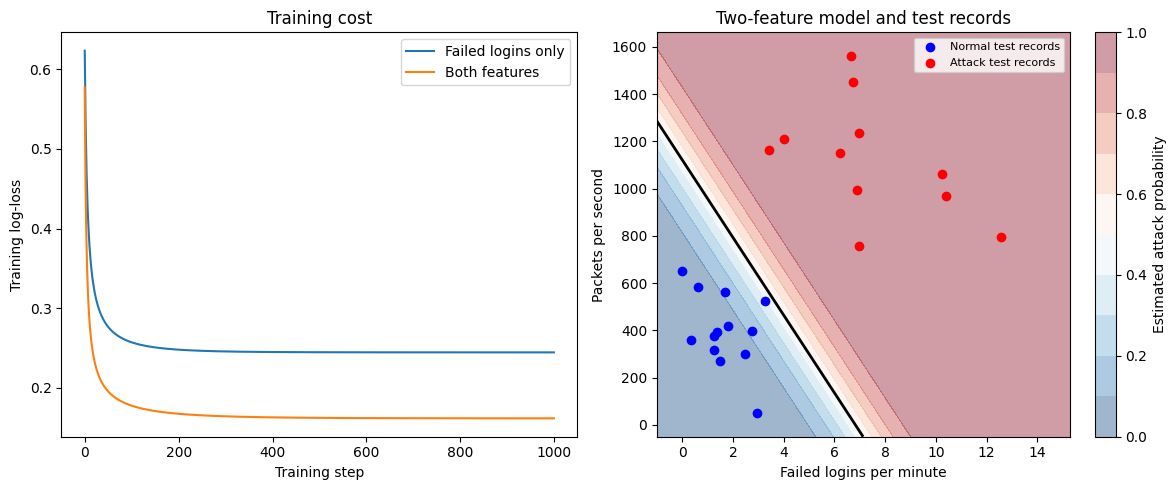

In [4]:
fig, (cost_ax, map_ax) = plt.subplots(1, 2, figsize=(12, 5)) # Make a cost graph and a traffic map.
cost_ax.plot(one_history, label="Failed logins only") # Draw cost while training the first model.
cost_ax.plot(two_history, label="Both features") # Draw cost while training the second model.
cost_ax.set_xlabel("Training step") # Label the cost graph's horizontal axis.
cost_ax.set_ylabel("Training log-loss") # Label the cost graph's vertical axis.
cost_ax.set_title("Training cost") # Give the cost graph a title.
cost_ax.legend() # Identify each model's cost line.

x_grid = np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, 120) # Make horizontal positions for the map.
y_grid = np.linspace(X[:, 1].min() - 100, X[:, 1].max() + 100, 120) # Make vertical positions for the map.
gx, gy = np.meshgrid(x_grid, y_grid) # Combine positions to cover the feature ranges.
grid = np.column_stack((gx.ravel(), gy.ravel())) # Turn each grid location into a two-feature record.
grid_scaled = (grid - mean) / sd # Scale grid records using the training averages and spreads.
grid_p = probabilities(grid_scaled, two_w, two_b).reshape(gx.shape) # Find attack probability across the grid.
shade = map_ax.contourf(gx, gy, grid_p, levels=np.linspace(0, 1, 11), cmap="RdBu_r", alpha=0.4) # Shade low-to-high attack probabilities.
fig.colorbar(shade, ax=map_ax, label="Estimated attack probability") # Show what the background colors mean.
if grid_p.min() < 0.5 < grid_p.max(): # Draw the boundary only if the grid contains both sides.
    map_ax.contour(gx, gy, grid_p, levels=[0.5], colors="black", linewidths=2) # Mark the 50 percent boundary.

# NOTE: X_test is already standardized, so convert it back to original units before plotting on the map.
X_test_raw = X_test * sd + mean
map_ax.scatter(X_test_raw[y_test == 0, 0], X_test_raw[y_test == 0, 1], color="blue", label="Normal test records") # Plot held-out normal records.
map_ax.scatter(X_test_raw[y_test == 1, 0], X_test_raw[y_test == 1, 1], color="red", label="Attack test records") # Plot held-out attack records.
map_ax.set_xlabel("Failed logins per minute") # Label the map's horizontal axis.
map_ax.set_ylabel("Packets per second") # Label the map's vertical axis.
map_ax.set_title("Two-feature model and test records") # Give the traffic map a title.
map_ax.legend(fontsize=8) # Identify the two kinds of test records.
fig.tight_layout() # Arrange both plots so their labels remain visible.
plt.show() # Display the cost graph and traffic map.

## Written answers

**1. Which model has lower test log-loss? What does its cost curve show during training?**

_Your answer here_

**2. As the threshold increases from 0.3 to 0.7, how do false alarms and missed attacks change?**

_Your answer here_

**3. Traffic map: which test records are on the wrong side of the black boundary? What does the colored background show?**

_Your answer here_

**4. Does changing the threshold change the test log-loss in this program? Why?**

_Your answer here_

**5. Choose a model and threshold. Support it with one result and state one trade-off.**

_Your answer here_